# Preparación de datos: campañas de depósitos bancarios (banco portugués)

Este cuaderno cubre dos bloques:

- **c) Preparación por columnas:** conversión de tipos, imputación de faltantes, creación y transformación de columnas.
- **d) Preparación por filas:** duplicados, filtrado de registros fuera de rango o irrelevantes, agrupación temporal/categórica.

## 0. Librerías, estilo y bitácora de decisiones

In [1]:
from pathlib import Path
from data_loader import cargar_csv_desde_zip

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 6), "axes.titlesize": 14,
                     "axes.titleweight": "bold", "axes.labelsize": 12, "savefig.dpi": 150})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)

COLOR_PRINCIPAL = "#1f4e79"
COLOR_SECUNDARIO = "#c55a11"

# Carpetas de salida
SALIDA_FIG = Path("figuras"); SALIDA_FIG.mkdir(exist_ok=True)
SALIDA_TAB = Path("tablas");  SALIDA_TAB.mkdir(exist_ok=True)

ORDEN_MESES = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
DIAS_MES = dict(zip(ORDEN_MESES, [31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]))  # feb = 29 (permisivo)

# ---- Bitácora de decisiones ----
decisiones = []
def registrar(fase, paso, decision, justificacion, afectados=None):
    # Guarda cada decisión de preparación con el número de filas resultante
    decisiones.append({"fase": fase, "paso": paso, "decision": decision,
                       "justificacion": justificacion, "registros_afectados": afectados,
                       "filas_despues": len(df) if "df" in globals() else None})
print("Entorno listo.")

Entorno listo.


## 1. Acceso a los datos y verificación de integración

Se localizan los cuatro archivos del repositorio UCI *Bank Marketing* y se comprueba que se leen completos, para confirmar el acceso a todos los datos y evaluar si los conjuntos se pueden integrar.

In [2]:
archivos = {"bank-full.csv": "Base principal (2008-2010)",
            "bank.csv": "Muestra 10 % de bank-full",
            "bank-additional-full.csv": "Versión ampliada con indicadores económicos",
            "bank-additional.csv": "Muestra 10 % de bank-additional-full"}
datos, inventario = {}, []
for nombre, rol in archivos.items():
    d = cargar_csv_desde_zip(nombre, sep=";")
    datos[nombre] = d
    inventario.append({"archivo": nombre, "rol": rol, "filas": len(d), "columnas": d.shape[1],
                       "nulos_NaN": int(d.isna().sum().sum())})
inventario = pd.DataFrame(inventario)
display(inventario)
inventario.to_csv(SALIDA_TAB / "01_inventario_archivos.csv", index=False)

,archivo,rol,filas,columnas,nulos_NaN
0,bank-full.csv,Base principal (2008-2010),45211,17,0
1,bank.csv,Muestra 10 % de bank-full,4521,17,0
2,bank-additional-full.csv,Versión ampliada con indicadores económicos,41188,21,0
3,bank-additional.csv,Muestra 10 % de bank-additional-full,4119,21,0


### 1.1 Integración de los conjuntos

Se hacen tres comprobaciones: (1) si `bank.csv` está contenido en `bank-full.csv`, (2) qué columnas comparten `bank-full` y `bank-additional-full`, y (3) si existe una llave que permita unirlos sin generar filas falsas.

In [3]:
full = datos["bank-full.csv"]; muestra = datos["bank.csv"]; adicional = datos["bank-additional-full.csv"]

# (1) bank.csv dentro de bank-full.csv: se cruzan TODAS las columnas
cruce = muestra.merge(full.drop_duplicates(), how="left", indicator=True)
print("(1) Filas de bank.csv que SÍ aparecen en bank-full.csv:",
      f"{(cruce['_merge'] == 'both').sum():,} de {len(muestra):,}")

# (2) Columnas compartidas y exclusivas
comunes = sorted(set(full.columns) & set(adicional.columns))
solo_full = sorted(set(full.columns) - set(adicional.columns))
solo_add = sorted(set(adicional.columns) - set(full.columns))
print("(2) Columnas comunes:", comunes)
print("    Solo en bank-full:", solo_full)
print("    Solo en bank-additional:", solo_add)

(1) Filas de bank.csv que SÍ aparecen en bank-full.csv: 4,521 de 4,521
(2) Columnas comunes: ['age', 'campaign', 'contact', 'default', 'duration', 'education', 'housing', 'job', 'loan', 'marital', 'month', 'pdays', 'poutcome', 'previous', 'y']
    Solo en bank-full: ['balance', 'day']
    Solo en bank-additional: ['cons.conf.idx', 'cons.price.idx', 'day_of_week', 'emp.var.rate', 'euribor3m', 'nr.employed']


In [4]:
# (3) Búsqueda de llave: no existe ID de cliente, se prueba con las variables demográficas comunes.
print("Categorías de education en bank-full:      ", sorted(full["education"].unique()))
print("Categorías de education en bank-additional:", sorted(adicional["education"].unique()))

llave = ["age", "job", "marital", "education", "default", "housing", "loan"]
tam_full = full.groupby(llave).size().rename("n_full")
tam_add = adicional.groupby(llave).size().rename("n_add")
pareadas = pd.concat([tam_full, tam_add], axis=1).dropna()

filas_con_pareja = int(pareadas["n_full"].sum())
pares = int((pareadas["n_full"] * pareadas["n_add"]).sum())
print(f"\nFilas de bank-full con alguna coincidencia en bank-additional: {filas_con_pareja:,} de {len(full):,} "
      f"({filas_con_pareja / len(full):.1%})")
print(f"Filas que produciría el merge: {pares:,} -> {pares / filas_con_pareja:.1f} parejas por cada fila (relación muchos-a-muchos)")
print(f"Duplicados exactos en bank-additional-full: {adicional.duplicated().sum()}")

Categorías de education en bank-full:       ['primary', 'secondary', 'tertiary', 'unknown']
Categorías de education en bank-additional: ['basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'illiterate', 'professional.course', 'university.degree', 'unknown']

Filas de bank-full con alguna coincidencia en bank-additional: 909 de 45,211 (2.0%)
Filas que produciría el merge: 2,039 -> 2.2 parejas por cada fila (relación muchos-a-muchos)
Duplicados exactos en bank-additional-full: 12


**Interpretación.** `bank.csv` es una submuestra exacta de `bank-full.csv`, por lo que **no aporta datos nuevos**. `bank-additional` usa **otra codificación** (por ejemplo, `education` pasa de `primary/secondary/tertiary` a `basic.4y/university.degree/...`), tiene otras columnas (indicadores económicos, `day_of_week` en vez de `day`, sin `balance`) y **no tiene identificador de cliente**. Al unirlos por variables demográficas casi ninguna fila encuentra pareja y las que la encuentran se emparejan con **varias** filas a la vez (muchos-a-muchos): el resultado serían clientes inventados, no una ampliación. Decisión: **no fusionar**; se trabaja con `bank-full.csv` (coherente con los AED) y `bank-additional` queda como referencia bibliográfica del artículo base.

In [5]:
df = full.copy()
registrar("Integración", "Selección de fuente", "Se usa solo bank-full.csv; no se fusiona con bank.csv ni bank-additional",
          "bank.csv es subconjunto exacto; bank-additional usa otra codificación y no tiene llave común (merge muchos-a-muchos)", 0)
print("Base de trabajo:", df.shape)

Base de trabajo: (45211, 17)


## 2. c) Preparación de datos por columnas

### 2.1 Conversión de tipos de datos

Cada columna se convierte al tipo que representa su naturaleza: texto repetitivo → categoría, `y` (yes/no) → 0/1 y `month` → categoría **ordenada**. Con esto se ahorra memoria, se evita el orden alfabético de los meses y `y` queda como variable objetivo numérica.

In [6]:
tipos_antes = df.dtypes.astype(str).rename("tipo_antes")
memoria_antes = df.memory_usage(deep=True).sum() / 1024**2

CAT_NOMINALES = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]

df["yb"] = (df["y"] == "yes").astype("int8")                       # 1 = contrató el depósito
for c in CAT_NOMINALES:
    df[c] = df[c].astype("category")
df["month"] = pd.Categorical(df["month"], categories=ORDEN_MESES, ordered=True)
df["y"] = df["y"].astype("category")
for c in ["age", "day", "campaign", "previous"]:
    df[c] = pd.to_numeric(df[c], downcast="integer")

comparacion = pd.concat([tipos_antes, df.dtypes.astype(str).rename("tipo_despues")], axis=1)
display(comparacion)
print(f"Memoria: {memoria_antes:.1f} MB -> {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
registrar("Columnas", "Conversión de tipos", "8 variables → category, month → categoría ordenada, y → yb (0/1), enteros reducidos",
          "Memoria, orden cronológico correcto de meses y variable objetivo numérica", len(CAT_NOMINALES) + 3)

,tipo_antes,tipo_despues
age,int64,int8
job,str,category
marital,str,category
education,str,category
default,str,category
balance,int64,int64
housing,str,category
loan,str,category
contact,str,category
day,int64,int8


Memoria: 29.2 MB -> 1.7 MB


### 2.2 Reconstrucción de la fecha de contacto

El archivo trae `day` y `month` pero **no el año**. Los registros están en orden cronológico (mayo 2008 → noviembre 2010, según la documentación UCI), por lo que cada vez que el mes *retrocede* respecto al registro anterior empieza un año nuevo. La fecha reconstruida permite agrupar por año y trimestre (sección 3.3).

Es una **reconstrucción basada en el orden del archivo**, no un dato original. Por eso se hace **antes** de cualquier filtrado de filas y se valida abajo.

In [7]:
mes_num = df["month"].map({m: i + 1 for i, m in enumerate(ORDEN_MESES)}).astype(int)
retroceso = (mes_num.diff() < 0).astype(int)       # 1 cuando el mes baja (cambio de año)
anio = 2008 + retroceso.cumsum()

df["mes_num"] = mes_num.astype("int8")
df["anio"] = anio.astype("int16")
df["fecha_contacto"] = pd.to_datetime({"year": df["anio"], "month": df["mes_num"], "day": df["day"]})

# Validación: meses que caen en cada año reconstruido
display(pd.crosstab(df["anio"], df["month"])[ORDEN_MESES])
print("Rango de fechas:", df["fecha_contacto"].min().date(), "→", df["fecha_contacto"].max().date())
print("Fechas inválidas (NaT):", df["fecha_contacto"].isna().sum())
registrar("Columnas", "Fecha de contacto", "Se reconstruyó anio y fecha_contacto usando el orden del archivo (cada retroceso de mes = año nuevo)",
          "El año no existe en el CSV; supuesto documentado (UCI: datos ordenados cronológicamente 2008-2010)", len(df))

month,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
anio,,,,,,,,,,,,
2008,0,0,0,0,7957,4486,6380,5215,0,80,3598,13
2009,1176,2296,258,2718,5575,642,207,772,282,438,297,201
2010,227,353,219,214,234,213,308,260,297,220,75,0


Rango de fechas: 2008-05-05 → 2010-11-17
Fechas inválidas (NaT): 0


**Interpretación.** La tabla es coherente con la documentación: 2008 empieza en mayo, 2009 cubre los 12 meses y 2010 termina en noviembre. No hay fechas inválidas. Los meses con pocos registros (octubre y diciembre de 2008) deben interpretarse con cautela.

### 2.3 Imputación de valores faltantes

El diagnóstico de los AED mostró que no hay `NaN`, pero cuatro columnas usan el texto `unknown` como dato faltante. Un modelo no distingue entre "dato desconocido" y una categoría real, por lo que el tratamiento se decide columna por columna.

In [8]:
cols_unknown = ["job", "education", "contact", "poutcome"]
diag = pd.DataFrame({
    "unknown": [(df[c] == "unknown").sum() for c in cols_unknown],
    "porcentaje_%": [(df[c] == "unknown").mean() * 100 for c in cols_unknown],
    "tasa_contratacion_unknown_%": [df.loc[df[c] == "unknown", "yb"].mean() * 100 for c in cols_unknown],
}, index=cols_unknown)
display(diag)
print(f"Tasa global de contratación: {df['yb'].mean() * 100:.2f} %")
diag.to_csv(SALIDA_TAB / "02_diagnostico_unknown.csv")

,unknown,porcentaje_%,tasa_contratacion_unknown_%
job,288,0.64,11.81
education,1857,4.11,13.57
contact,13020,28.80,4.07
poutcome,36959,81.75,9.16


Tasa global de contratación: 11.70 %


**Decisión por columna:**

| Columna | % unknown | Decisión | Motivo |
|---|---|---|---|
| `job` | 0,6 % | Imputar con la **moda según rango de edad** | Muy pocos casos; la ocupación depende de la edad (estudiantes jóvenes, jubilados mayores) |
| `education` | 4,1 % | Imputar con la **moda según ocupación** | La educación depende fuertemente de la ocupación (gerencia → superior) |
| `contact` | 28,8 % | **Conservar** `unknown` como categoría | Es mucho y su tasa de contratación es muy distinta (señal, no ruido) |
| `poutcome` | 81,8 % | **Conservar** `unknown` (= sin campaña previa) | No es un dato perdido: es ausencia de historial. Imputarlo sería inventarlo |

Cada imputación deja una **bandera** (`*_imputada`) para poder auditarla y para que el modelo la use si resulta informativa.

In [9]:
# Rango de edad (auxiliar para imputar job; se reutiliza en 2.4)
BINS_EDAD = [17, 25, 35, 45, 55, 65, 100]
ETQ_EDAD = ["18-25", "26-35", "36-45", "46-55", "56-65", "66 o más"]
df["rango_edad"] = pd.cut(df["age"], bins=BINS_EDAD, labels=ETQ_EDAD)

educ_antes = df["education"].value_counts(normalize=True).mul(100).rename("antes_%")

# ---- job: moda por rango de edad ----
df["job_imputada"] = (df["job"] == "unknown")
job_conocido = df[~df["job_imputada"]]
moda_job = job_conocido.groupby("rango_edad", observed=True)["job"].agg(lambda s: s.mode().iloc[0])
idx = df.index[df["job_imputada"]]
df["job"] = df["job"].astype(object)
df.loc[idx, "job"] = df.loc[idx, "rango_edad"].astype(str).map(moda_job.rename(index=str))
df["job"] = df["job"].astype("category")

# ---- education: moda por ocupación (ya imputada) ----
df["education_imputada"] = (df["education"] == "unknown")
educ_conocida = df[~df["education_imputada"]]
moda_educ = educ_conocida.groupby("job", observed=True)["education"].agg(lambda s: s.mode().iloc[0])
idx = df.index[df["education_imputada"]]
df["education"] = df["education"].astype(object)
df.loc[idx, "education"] = df.loc[idx, "job"].astype(str).map(moda_educ.rename(index=str))
df["education"] = df["education"].astype("category")

print("Moda de job por rango de edad:"); display(moda_job.to_frame("moda_job"))
print("Moda de education por job:");     display(moda_educ.to_frame("moda_education"))
print("Quedan 'unknown' en job:", (df["job"] == "unknown").sum(), "| en education:", (df["education"] == "unknown").sum())

Moda de job por rango de edad:


,moda_job
rango_edad,
18-25,student
26-35,management
36-45,blue-collar
46-55,blue-collar
56-65,retired
66 o más,retired


Moda de education por job:


,moda_education
job,
admin.,secondary
blue-collar,secondary
entrepreneur,tertiary
housemaid,primary
management,tertiary
retired,secondary
self-employed,tertiary
services,secondary
student,secondary


Quedan 'unknown' en job: 0 | en education: 0


In [10]:
# Validación: la imputación no debe distorsionar la distribución ni la tasa de contratación
educ_despues = df["education"].value_counts(normalize=True).mul(100).rename("despues_%")
comp_educ = pd.concat([educ_antes, educ_despues], axis=1).fillna(0)
display(comp_educ)
comp_educ.to_csv(SALIDA_TAB / "03_education_antes_despues.csv")

tasa_flag = df.groupby("education_imputada")["yb"].agg(clientes="size", tasa_pct=lambda s: s.mean() * 100)
display(tasa_flag)
registrar("Columnas", "Imputación job", "'unknown' → moda según rango de edad + bandera job_imputada",
          "0,6 % de casos; ocupación asociada a la edad", int(df["job_imputada"].sum()))
registrar("Columnas", "Imputación education", "'unknown' → moda según ocupación + bandera education_imputada",
          "4,1 % de casos; educación asociada a la ocupación", int(df["education_imputada"].sum()))
registrar("Columnas", "contact / poutcome", "'unknown' se conserva como categoría",
          "contact: 28,8 % y tasa distinta (señal); poutcome: significa 'sin campaña previa' (dato estructural)",
          int(((df["contact"] == "unknown") | (df["poutcome"] == "unknown")).sum()))

,antes_%,despues_%
education,,
secondary,51.32,54.52
tertiary,29.42,30.23
primary,15.15,15.25
unknown,4.11,0.00


,clientes,tasa_pct
education_imputada,,
False,43354,11.62
True,1857,13.57


**Interpretación.** La imputación por moda **refuerza** la categoría dominante (por ejemplo, `secondary`), un sesgo conocido y aceptado por ser un porcentaje bajo. La tabla "antes/después" permite verificar que el cambio es pequeño. La imputación no cambia `y`: los registros imputados mantienen su tasa de contratación (13,6 % frente a 11,6 % del resto), una diferencia moderada que ya aparecía en el AED 2 para la categoría `unknown`. Las banderas dejan el rastro para auditarlo.

### 2.4 Tratamiento de `pdays` (faltante estructural)

`pdays = -1` no es un número: significa "nunca contactado antes". Tratarlo como un número real (−1 días) distorsiona cualquier media o distancia.

**Decisión:** crear `contactado_antes` (0/1) y `dias_desde_contacto_previo` con `NaN` donde no hubo contacto. **No se imputa** con la media: el dato no existe, no se perdió. (`contactado_antes` se usa en el análisis; no pasa a la tabla minable por ser redundante, ver 4.1.)

In [11]:
# Coherencia entre pdays y previous (condición para poder derivar la bandera)
incoherentes = ((df["pdays"] == -1) != (df["previous"] == 0)).sum()
print("Registros donde (pdays = -1) no coincide con (previous = 0):", incoherentes)

df["contactado_antes"] = (df["pdays"] != -1).astype("int8")
df["dias_desde_contacto_previo"] = df["pdays"].where(df["pdays"] != -1)   # NaN si nunca contactado
print(f"Contactados antes: {df['contactado_antes'].sum():,} ({df['contactado_antes'].mean():.1%}) | "
      f"NaN estructurales en dias_desde_contacto_previo: {df['dias_desde_contacto_previo'].isna().sum():,}")
registrar("Columnas", "pdays", "pdays = -1 → NaN en dias_desde_contacto_previo + bandera contactado_antes (sin imputar)",
          "-1 significa 'nunca contactado'; es un faltante estructural, no un valor numérico", int((df["pdays"] == -1).sum()))

Registros donde (pdays = -1) no coincide con (previous = 0): 0
Contactados antes: 8,257 (18.3%) | NaN estructurales en dias_desde_contacto_previo: 36,954


### 2.5 Creación y transformación de nuevas columnas

Columnas derivadas a partir de los hallazgos del AED 2 (relaciones no lineales, asimetría de `balance`, saturación de `campaign`), que dan al modelo versiones más informativas y estables de las variables originales.

| Columna nueva | Cómo se construye | Por qué |
|---|---|---|
| `balance_log` | log con signo: `sign(x)·log(1+|x|)` | `balance` es muy asimétrico y tiene negativos (no admite log simple) |
| `balance_negativo` | `balance < 0` | Cliente sobregirado: grupo con comportamiento propio |
| `cuartil_saldo` | `qcut` en 4 grupos | Relación creciente y estable con la contratación (AED 2) |
| `campaign_cap`, `previous_cap` | tope fijo en 10 | Más de 10 contactos tiene tasa casi constante; evita que valores como 63 o 275 dominen |
| `n_deudas`, `tiene_deuda` | housing + loan | Resume dos señales negativas parecidas |
| `rango_contactos` | bins del AED 2 | Pérdida de interés a más llamadas |
| `trimestre` | de `fecha_contacto` | Estacionalidad de la campaña |

`n_deudas` y `tiene_deuda` se conservan en la base de análisis, pero `n_deudas` no pasa a la tabla minable por ser una suma exacta de `housing_bin` y `loan_bin` (ver 4.1).

Los topes son **reglas fijas** (no percentiles calculados con todos los datos), para no filtrar información del conjunto de prueba cuando llegue el modelado.

In [12]:
# balance
df["balance_negativo"] = (df["balance"] < 0).astype("int8")
df["balance_log"] = np.sign(df["balance"]) * np.log1p(df["balance"].abs())
df["cuartil_saldo"] = pd.qcut(df["balance"], 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])

# contactos (tope fijo = 10)
TOPE = 10
df["campaign_cap"] = df["campaign"].clip(upper=TOPE).astype("int8")
df["previous_cap"] = df["previous"].clip(upper=TOPE).astype("int8")
df["rango_contactos"] = pd.cut(df["campaign"], bins=[0, 1, 2, 3, 5, 10, 100],
                               labels=["1", "2", "3", "4-5", "6-10", "Más de 10"])

# binarias y deuda
for c in ["default", "housing", "loan"]:
    df[c + "_bin"] = (df[c] == "yes").astype("int8")
df["n_deudas"] = (df["housing_bin"] + df["loan_bin"]).astype("int8")
df["tiene_deuda"] = (df["n_deudas"] > 0).astype("int8")

# tiempo
df["trimestre"] = df["fecha_contacto"].dt.to_period("Q").astype(str)

nuevas = ["yb", "mes_num", "anio", "fecha_contacto", "rango_edad", "job_imputada", "education_imputada",
          "contactado_antes", "dias_desde_contacto_previo", "balance_negativo", "balance_log", "cuartil_saldo",
          "campaign_cap", "previous_cap", "rango_contactos", "default_bin", "housing_bin", "loan_bin",
          "n_deudas", "tiene_deuda", "trimestre"]
print(f"Columnas nuevas: {len(nuevas)} | Total de columnas ahora: {df.shape[1]}")
registrar("Columnas", "Nuevas columnas", f"Se crearon {len(nuevas)} columnas derivadas (balance_log, campaign_cap, n_deudas, trimestre, etc.)",
          "Capturan relaciones no lineales y reducen el efecto de valores extremos (hallazgos del AED 2)", len(nuevas))

Columnas nuevas: 21 | Total de columnas ahora: 38


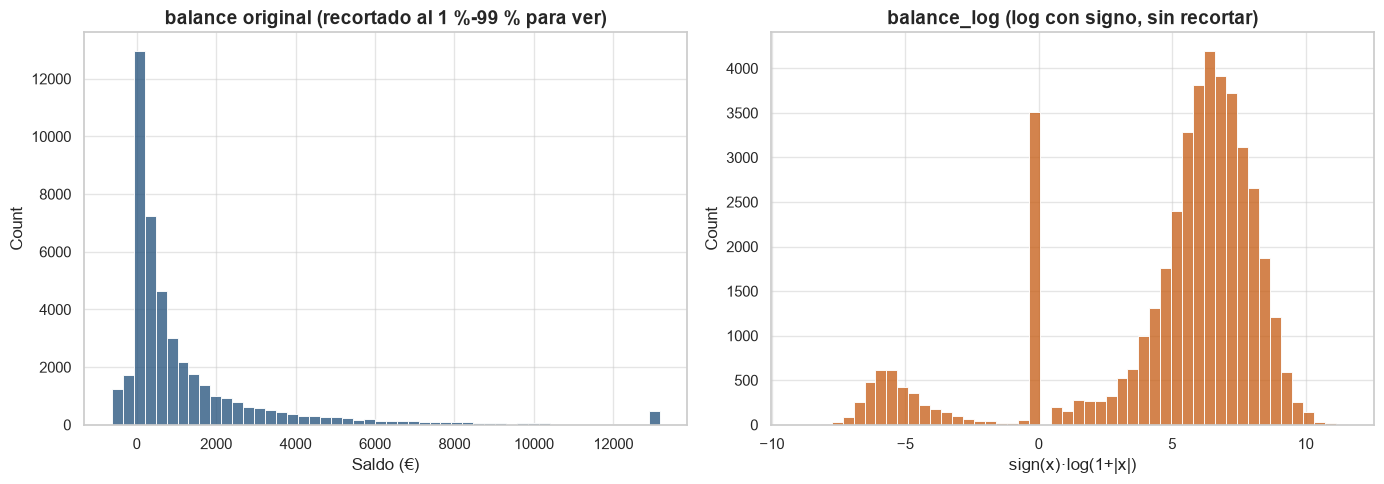

Asimetría (skew): original = 8.36 | balance_log = -1.58
Clientes con saldo exactamente 0: 3,514 | con saldo negativo: 3,766


In [13]:
# Efecto de la transformación sobre balance
lim_inf, lim_sup = df["balance"].quantile([0.01, 0.99])
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["balance"].clip(lim_inf, lim_sup), bins=50, color=COLOR_PRINCIPAL, edgecolor="white", ax=ejes[0])
ejes[0].set_title("balance original (recortado al 1 %-99 % para ver)"); ejes[0].set_xlabel("Saldo (€)")
sns.histplot(df["balance_log"], bins=50, color=COLOR_SECUNDARIO, edgecolor="white", ax=ejes[1])
ejes[1].set_title("balance_log (log con signo, sin recortar)"); ejes[1].set_xlabel("sign(x)·log(1+|x|)")
plt.tight_layout(); plt.savefig(SALIDA_FIG / "fig1_balance_log.png", bbox_inches="tight"); plt.show()
print(f"Asimetría (skew): original = {df['balance'].skew():.2f} | balance_log = {df['balance_log'].skew():.2f}")
print(f"Clientes con saldo exactamente 0: {(df['balance'] == 0).sum():,} | con saldo negativo: {(df['balance'] < 0).sum():,}")

**Interpretación.** El saldo original queda comprimido contra el cero con una cola muy larga (asimetría 8,4). Con el logaritmo con signo, la parte positiva (la gran mayoría) queda casi simétrica y los valores extremos dejan de dominar, sin eliminar ningún cliente. La distribución **no es una sola campana**: hay un pico en 0 (clientes con saldo exactamente 0) y un grupo separado de saldos negativos. Por eso, además de `balance_log`, se conserva la bandera `balance_negativo`.

### 2.6 Revisión de formato antes del modelado

Se listan las columnas que **todavía no** se pueden pasar a un algoritmo y el motivo, y se señalan los problemas de formato pendientes.

In [14]:
FEATURES_EXCLUIDAS = {
    "duration": "Fuga de información: solo se conoce al terminar la llamada (advertencia del AED 2)",
    "y / yb": "Es la variable objetivo",
    "pdays": "Reemplazada por dias_desde_contacto_previo (0 = sin contacto previo); contactado_antes queda solo en la base de análisis",
    "fecha_contacto, anio, trimestre": "Año reconstruido (no es dato original) y no estaría disponible igual en producción",
    "rango_edad, cuartil_saldo, rango_contactos": "Versiones agrupadas de variables numéricas ya incluidas (solo para análisis)",
}
pendientes = pd.DataFrame({"columna": list(FEATURES_EXCLUIDAS), "motivo_exclusion": list(FEATURES_EXCLUIDAS.values())})
display(pendientes)
pendientes.to_csv(SALIDA_TAB / "04_columnas_excluidas_modelo.csv", index=False)

print("\nProblemas de formato pendientes para el modelado:")
print(" - Variables categóricas de texto (job, marital, education, contact, month, poutcome): requieren codificación (one-hot).")
print(" - dias_desde_contacto_previo tiene NaN estructurales: se rellena con 0 (el mínimo real de pdays es 1, así que el 0 identifica a quien no tuvo contacto previo; ver sección 4).")
print(" - Escalas muy distintas (age, day, balance_log...): el escalado se hará DENTRO de un Pipeline, después de dividir train/test.")
registrar("Columnas", "Exclusión de variables", "duration, pdays original y variables de fecha/agrupadas se excluyen de las features",
          "duration es fuga de información; las demás son redundantes o no disponibles en producción", None)

,columna,motivo_exclusion
0,duration,Fuga de información: solo se conoce al termina...
1,y / yb,Es la variable objetivo
2,pdays,Reemplazada por dias_desde_contacto_previo (0 ...
3,"fecha_contacto, anio, trimestre",Año reconstruido (no es dato original) y no es...
4,"rango_edad, cuartil_saldo, rango_contactos",Versiones agrupadas de variables numéricas ya ...



Problemas de formato pendientes para el modelado:
 - Variables categóricas de texto (job, marital, education, contact, month, poutcome): requieren codificación (one-hot).
 - dias_desde_contacto_previo tiene NaN estructurales: se rellena con 0 (el mínimo real de pdays es 1, así que el 0 identifica a quien no tuvo contacto previo; ver sección 4).
 - Escalas muy distintas (age, day, balance_log...): el escalado se hará DENTRO de un Pipeline, después de dividir train/test.


## 3. d) Preparación de datos por filas

### 3.1 Eliminación de duplicados

Se buscan registros idénticos de dos formas: duplicados exactos (todas las columnas) y duplicados en las variables predictoras ignorando `y` (mismo perfil con respuestas distintas, lo que sería una contradicción).

In [15]:
n_exactos = df.drop(columns=["fecha_contacto"]).duplicated(subset=[c for c in full.columns]).sum()
n_sin_y = df.duplicated(subset=[c for c in full.columns if c != "y"]).sum()
print("Duplicados exactos (17 columnas originales):", n_exactos)
print("Duplicados ignorando y (mismo perfil, posible contradicción):", n_sin_y)

antes = len(df)
df = df.drop_duplicates(subset=list(full.columns)).reset_index(drop=True)
print(f"Filas: {antes:,} → {len(df):,}")
registrar("Filas", "Duplicados", "Se verificó y se aplicó drop_duplicates sobre las 17 columnas originales",
          "Cero duplicados exactos ni contradictorios; la llamada incluye día, mes, duración y saldo, que casi nunca coinciden", int(antes - len(df)))

Duplicados exactos (17 columnas originales): 0
Duplicados ignorando y (mismo perfil, posible contradicción): 0
Filas: 45,211 → 45,211


**Interpretación.** No hay duplicados. Es el resultado esperado: dos clientes distintos casi nunca coinciden a la vez en edad, saldo, día, mes y duración de llamada. Se deja la instrucción `drop_duplicates` para que el proceso sea reproducible si cambian los datos. (En cambio, `bank-additional-full.csv` sí trae 12 duplicados, otro motivo para no mezclarlos.)

### 3.2 Filtrado de registros fuera de rango o irrelevantes

Tabla de reglas de validez: cada regla cuenta cuántos registros la incumplen y se decide si **eliminar**, **conservar** o **tratar** (capar/transformar).

**Criterio:** solo se **eliminan** filas cuando el dato es imposible o no representa un contacto real. Los valores extremos pero posibles (saldos altos, muchos contactos) se **conservan** y se tratan en columnas.

In [16]:
def n_atipicos_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75]); r = q3 - q1
    return int(((s < q1 - 1.5 * r) | (s > q3 + 1.5 * r)).sum())

reglas = [
    ("age fuera de 18-100",                   int((~df["age"].between(18, 100)).sum()),                          "Conservar (ninguno)"),
    ("day fuera de 1-31",                     int((~df["day"].between(1, 31)).sum()),                            "Conservar (ninguno)"),
    ("day imposible para el mes (ej. 31 jun)", int((df["day"] > df["month"].astype(str).map(DIAS_MES)).sum()),   "Conservar (ninguno)"),
    ("campaign < 1",                          int((df["campaign"] < 1).sum()),                                   "Conservar (ninguno)"),
    ("pdays < -1",                            int((df["pdays"] < -1).sum()),                                     "Conservar (ninguno)"),
    ("pdays/previous incoherentes",           int(((df["pdays"] == -1) != (df["previous"] == 0)).sum()),         "Conservar (ninguno)"),
    ("poutcome = unknown pero con pdays ≠ -1", int(((df["poutcome"] == "unknown") & (df["pdays"] != -1)).sum()), "Conservar y reportar (leve inconsistencia)"),
    ("duration = 0 s (llamada sin contacto real)", int((df["duration"] == 0).sum()),                             "ELIMINAR"),
    ("previous > 50 (valores como 275)",      int((df["previous"] > 50).sum()),                                  "Conservar; tratado con previous_cap"),
    ("campaign > 10",                         int((df["campaign"] > 10).sum()),                                  "Conservar; tratado con campaign_cap"),
    ("balance atípico (IQR)",                 n_atipicos_iqr(df["balance"]),                                     "Conservar; tratado con balance_log"),
    ("balance negativo",                      int((df["balance"] < 0).sum()),                                    "Conservar; bandera balance_negativo"),
]
validaciones = pd.DataFrame(reglas, columns=["regla", "registros_que_incumplen", "accion"])
display(validaciones)
validaciones.to_csv(SALIDA_TAB / "05_validaciones_filas.csv", index=False)

,regla,registros_que_incumplen,accion
0,age fuera de 18-100,0,Conservar (ninguno)
1,day fuera de 1-31,0,Conservar (ninguno)
2,day imposible para el mes (ej. 31 jun),0,Conservar (ninguno)
3,campaign < 1,0,Conservar (ninguno)
4,pdays < -1,0,Conservar (ninguno)
5,pdays/previous incoherentes,0,Conservar (ninguno)
6,poutcome = unknown pero con pdays ≠ -1,5,Conservar y reportar (leve inconsistencia)
7,duration = 0 s (llamada sin contacto real),3,ELIMINAR
8,previous > 50 (valores como 275),4,Conservar; tratado con previous_cap
9,campaign > 10,1196,Conservar; tratado con campaign_cap


**Interpretación.** Los datos son consistentes: no hay edades, días ni fechas imposibles. La única regla que justifica eliminar filas es `duration = 0`: son llamadas donde no hubo conversación (en todas, `y = no`) y por tanto **no son un contacto real**. Los valores extremos de `balance`, `campaign` y `previous` son posibles, así que se conservan y se controlan con columnas transformadas.

In [17]:
print("Respuesta (y) de las llamadas de 0 s:", df.loc[df["duration"] == 0, "yb"].value_counts().to_dict())
antes = len(df)
df = df[df["duration"] > 0].reset_index(drop=True)
print(f"Filas: {antes:,} → {len(df):,}  (eliminadas: {antes - len(df)})")
registrar("Filas", "Filtrado duration = 0", "Se eliminan los registros con duration = 0",
          "Llamadas sin conversación: no representan un contacto real (todas con y = no)", int(antes - len(df)))
registrar("Filas", "Valores extremos", "No se eliminan atípicos de balance, campaign ni previous",
          "Son valores posibles del negocio; se tratan con balance_log y topes campaign_cap / previous_cap", None)

Respuesta (y) de las llamadas de 0 s: {0: 3}
Filas: 45,211 → 45,208  (eliminadas: 3)


### 3.3 Agrupación de datos por categorías temporales y de perfil

Se resumen los clientes por periodo y por grupo, con la cantidad de contactos y la **tasa de contratación**. La agrupación confirma que las columnas de fecha son útiles, detecta periodos con muy pocos datos y simplifica la ocupación (12 categorías) en pocos grupos de negocio.

**Nota geográfica:** el conjunto **no tiene ninguna variable geográfica** (región, ciudad, sucursal), por lo que no se puede agrupar por zona. Queda como limitación.

In [18]:
def resumen_tasa(data, por):
    return data.groupby(por, observed=True).agg(
        clientes=("yb", "size"), contrataron=("yb", "sum"),
        tasa_pct=("yb", lambda s: s.mean() * 100)).round(2)

# Por año y trimestre
tabla_trim = resumen_tasa(df, "trimestre")
display(tabla_trim)
tabla_trim.to_csv(SALIDA_TAB / "06_tasa_por_trimestre.csv")

# Por año-mes (para la figura)
df["periodo"] = df["fecha_contacto"].dt.to_period("M").astype(str)
tabla_mes = resumen_tasa(df, "periodo")

,clientes,contrataron,tasa_pct
trimestre,,,
2008Q2,12442,459,3.69
2008Q3,11594,672,5.80
2008Q4,3691,270,7.32
2009Q1,3730,418,11.21
2009Q2,8934,1225,13.71
2009Q3,1261,463,36.72
2009Q4,936,430,45.94
2010Q1,799,413,51.69
2010Q2,661,364,55.07


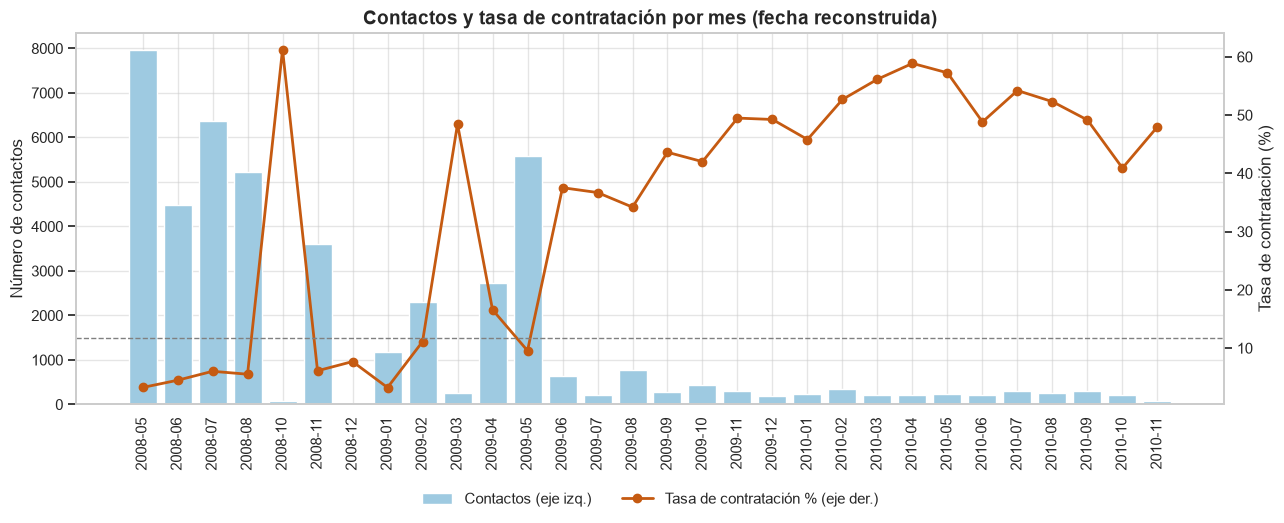

In [19]:
fig, ax1 = plt.subplots(figsize=(13, 5.5))
ax1.bar(tabla_mes.index, tabla_mes["clientes"], color="#9ecae1", label="Contactos (eje izq.)")
ax1.set_ylabel("Número de contactos"); ax1.tick_params(axis="x", rotation=90)
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(tabla_mes.index, tabla_mes["tasa_pct"], color=COLOR_SECUNDARIO, marker="o", linewidth=2, label="Tasa de contratación % (eje der.)")
ax2.axhline(df["yb"].mean() * 100, color="gray", linestyle="--", linewidth=1)
ax2.set_ylabel("Tasa de contratación (%)")
ax1.set_title("Contactos y tasa de contratación por mes (fecha reconstruida)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(SALIDA_FIG / "fig2_tasa_mensual.png", bbox_inches="tight"); plt.show()

**Interpretación.** El volumen de llamadas se concentra en unos pocos meses de 2008 y comienzos de 2009, mientras que 2010 tiene un volumen bajo y estable. La tasa de contratación **sube cuando el volumen baja**: los meses con pocas llamadas (campañas más selectivas) tienen tasas mucho más altas que mayo. La línea gris marca la tasa global. Los periodos con muy pocos contactos (por ejemplo, diciembre de 2008) tienen tasas inestables y no deben interpretarse de forma aislada.

In [20]:
# Agrupación de ocupación en 4 grupos de negocio (decisión documentada)
GRUPOS_JOB = {
    "management": "Profesional / directivo", "admin.": "Profesional / directivo", "technician": "Profesional / directivo",
    "blue-collar": "Operativo / servicios", "services": "Operativo / servicios", "housemaid": "Operativo / servicios",
    "entrepreneur": "Independiente", "self-employed": "Independiente",
    "student": "Sin actividad laboral", "retired": "Sin actividad laboral", "unemployed": "Sin actividad laboral",
}
df["grupo_ocupacion"] = df["job"].astype(str).map(GRUPOS_JOB)
print("Ocupaciones sin grupo asignado:", df["grupo_ocupacion"].isna().sum())

tabla_grupo = resumen_tasa(df, "grupo_ocupacion").sort_values("tasa_pct", ascending=False)
display(tabla_grupo)
tabla_grupo.to_csv(SALIDA_TAB / "07_tasa_por_grupo_ocupacion.csv")
registrar("Filas", "Agrupación temporal", "Se agrupa por año, trimestre y año-mes con conteo y tasa de contratación",
          "Valida la fecha reconstruida y detecta periodos con muy pocos contactos", None)
registrar("Filas", "Agrupación de ocupación", "12 ocupaciones → 4 grupos (profesional, operativo, independiente, sin actividad)",
          "Reduce categorías para análisis y permite comparar perfiles; no hay variable geográfica para agrupar por zona", None)

Ocupaciones sin grupo asignado: 0


,clientes,contrataron,tasa_pct
grupo_ocupacion,,,
Sin actividad laboral,4578,994,21.71
Profesional / directivo,22267,2779,12.48
Independiente,3065,310,10.11
Operativo / servicios,15298,1206,7.88


**Interpretación.** El grupo **sin actividad laboral** (estudiantes, jubilados y desempleados) contrata mucho más que el resto, y el grupo **operativo/servicios** contrata menos. La agrupación conserva el patrón visto en el AED 2 con menos categorías. La columna `grupo_ocupacion` es de análisis; en el modelo se usa `job` completo.

## 4. Conjunto final, verificación y exportación

Se arma la tabla lista para modelar (`df_modelo`): solo columnas numéricas, categóricas con one-hot y sin nulos. Antes de armarla (4.1) se retiran las columnas redundantes; luego (4.2) se construye la tabla, se verifica y se exportan los archivos.

### 4.1 Depuración de columnas redundantes (antes de armar la tabla minable)

Se retiran de la tabla minable las columnas cuya información se reconstruye exactamente con otras columnas que sí quedan, de modo que ningún modelo pierde información. Con esto se evitan columnas duplicadas que generan colinealidad en los modelos lineales. La base de análisis (`bank_full_preparado.csv`) conserva todas sus columnas.

| Columna que se retira | Se reconstruye con | Motivo |
|---|---|---|
| `n_deudas` | `housing_bin + loan_bin` | Suma exacta de dos columnas que sí quedan (dependencia lineal exacta) |
| `contactado_antes` | `dias_desde_contacto_previo > 0` | Los días rellenados con 0 ya distinguen a quien no tuvo contacto previo; además coincide con `1 − poutcome_unknown` salvo en 5 registros |

No se retiran las banderas de auditoría (`job_imputada`, `education_imputada`), `default_bin` ni las indicadoras de `job`, `contact`, `month` y `poutcome`: no se obtienen a partir de otras columnas y aportan información propia. `balance_negativo` también se conserva: aunque se deriva de `balance_log < 0`, en un modelo lineal aporta el salto en 0 que `balance_log` no representa.

In [21]:
# Verificación de redundancia con los datos (comprobación de columnas, no una prueba de modelo)
# Condición para que el 0 de dias_desde_contacto_previo no se confunda con un valor real: el mínimo real debe ser >= 1
assert df["dias_desde_contacto_previo"].min() >= 1

chequeos = [
    ("n_deudas", "housing_bin + loan_bin",
     int((df["n_deudas"] != df["housing_bin"] + df["loan_bin"]).sum()),
     "Suma exacta de dos columnas que sí quedan"),
    ("contactado_antes", "dias_desde_contacto_previo (NaN → 0) > 0",
     int((df["contactado_antes"] != (df["dias_desde_contacto_previo"].fillna(0) > 0).astype("int8")).sum()),
     "Los días con 0 ya identifican a quien no tuvo contacto previo"),
]
redundantes = pd.DataFrame(chequeos, columns=["columna_eliminada", "se_reconstruye_con", "registros_que_no_coinciden", "motivo"])
display(redundantes)

# Dato adicional: contactado_antes también coincide casi por completo con poutcome (sin campaña previa)
dif_poutcome = int((df["contactado_antes"] != (df["poutcome"] != "unknown").astype("int8")).sum())
print(f"contactado_antes vs (poutcome != 'unknown'): difieren en {dif_poutcome} registros ({dif_poutcome / len(df):.3%})")

# Si alguna reconstrucción no fuera exacta, el cuaderno se detiene y la columna no se retira
assert (redundantes["registros_que_no_coinciden"] == 0).all()
REDUNDANTES = list(redundantes["columna_eliminada"])
redundantes.to_csv(SALIDA_TAB / "04b_columnas_redundantes_eliminadas.csv", index=False)
print("Columnas que se retiran de la tabla minable:", REDUNDANTES)
registrar("Columnas", "Depuración de redundantes", "n_deudas y contactado_antes se retiran de la tabla minable (siguen en bank_full_preparado.csv)",
          "Se reconstruyen exactamente con columnas que sí quedan (housing_bin + loan_bin; dias_desde_contacto_previo > 0): evita colinealidad sin perder información",
          len(REDUNDANTES))

,columna_eliminada,se_reconstruye_con,registros_que_no_coinciden,motivo
0,n_deudas,housing_bin + loan_bin,0,Suma exacta de dos columnas que sí quedan
1,contactado_antes,dias_desde_contacto_previo (NaN → 0) > 0,0,Los días con 0 ya identifican a quien no tuvo ...


contactado_antes vs (poutcome != 'unknown'): difieren en 5 registros (0.011%)
Columnas que se retiran de la tabla minable: ['n_deudas', 'contactado_antes']


### 4.2 Armado de la tabla minable

Se seleccionan las columnas que quedan tras la depuración, se codifican las categóricas con one-hot (`drop_first=True`) y los `NaN` estructurales de `dias_desde_contacto_previo` pasan a 0.

In [22]:
# n_deudas y contactado_antes ya se retiraron en 4.1 (REDUNDANTES)
NUM = ["age", "day", "balance_log", "campaign_cap", "previous_cap"]
BIN = ["default_bin", "housing_bin", "loan_bin", "balance_negativo",
       "job_imputada", "education_imputada"]
CAT = ["job", "marital", "education", "contact", "month", "poutcome"]

X = df[NUM + BIN].copy()
X["dias_desde_contacto_previo"] = df["dias_desde_contacto_previo"].fillna(0)   # 0 = sin contacto previo (el mínimo real de pdays es 1)
X[["job_imputada", "education_imputada"]] = X[["job_imputada", "education_imputada"]].astype("int8")
dummies = pd.get_dummies(df[CAT].astype(str), prefix=CAT, drop_first=True, dtype="int8")
df_modelo = pd.concat([X, dummies], axis=1)
df_modelo["yb"] = df["yb"].values

print("df_modelo:", df_modelo.shape)
print("Nulos en df_modelo:", int(df_modelo.isna().sum().sum()))
print("Tipos no numéricos:", [c for c in df_modelo.columns if not np.issubdtype(df_modelo[c].dtype, np.number)])
registrar("Formato", "Codificación", "One-hot (drop_first) de job, marital, education, contact, month, poutcome; NaN de dias_desde_contacto_previo → 0",
          "Los algoritmos necesitan entradas numéricas; el 0 no se confunde con un valor real porque el mínimo de pdays es 1", df_modelo.shape[1] - 1)

df_modelo: (45208, 43)
Nulos en df_modelo: 0
Tipos no numéricos: []


In [23]:
# Verificaciones finales (si alguna falla, el cuaderno se detiene)
assert df_modelo.isna().sum().sum() == 0
assert df.duplicated(subset=list(full.columns)).sum() == 0
assert (df["duration"] > 0).all()
assert not (df["job"] == "unknown").any() and not (df["education"] == "unknown").any()
assert df["fecha_contacto"].notna().all()
assert set(df_modelo["yb"].unique()) <= {0, 1}
assert not set(REDUNDANTES) & set(df_modelo.columns)          # las redundantes no están en la tabla minable
predictoras = df_modelo.drop(columns="yb")
assert np.linalg.matrix_rank(predictoras.values.astype(float)) == predictoras.shape[1]   # sin dependencias lineales
print(f"Predictoras: {predictoras.shape[1]} | rango de la matriz: {np.linalg.matrix_rank(predictoras.values.astype(float))} (sin dependencias lineales)")

resumen = pd.DataFrame({
    "indicador": ["Filas originales (bank-full)", "Filas finales", "Filas eliminadas", "Columnas originales",
                  "Columnas tras preparación (análisis)", "Columnas en df_modelo (con la objetivo)",
                  "Tasa de contratación original %", "Tasa de contratación final %"],
    "valor": [f"{len(full):,}", f"{len(df):,}", f"{len(full) - len(df):,}", full.shape[1], df.shape[1], df_modelo.shape[1],
              f"{(full['y'] == 'yes').mean() * 100:.2f}", f"{df['yb'].mean() * 100:.2f}"]})
display(resumen)
resumen.to_csv(SALIDA_TAB / "08_resumen_final.csv", index=False)

Predictoras: 42 | rango de la matriz: 42 (sin dependencias lineales)


,indicador,valor
0,Filas originales (bank-full),"45,211"
1,Filas finales,"45,208"
2,Filas eliminadas,3
3,Columnas originales,17
4,Columnas tras preparación (análisis),40
5,Columnas en df_modelo (con la objetivo),43
6,Tasa de contratación original %,11.70
7,Tasa de contratación final %,11.70


In [24]:
bitacora = pd.DataFrame(decisiones)
bitacora["registros_afectados"] = bitacora["registros_afectados"].astype("Int64")
display(bitacora[["fase", "paso", "decision", "registros_afectados", "filas_despues"]])

bitacora.to_csv(SALIDA_TAB / "00_bitacora_decisiones.csv", index=False)
df.to_csv("bank_full_preparado.csv", index=False)
df_modelo.to_csv("bank_full_modelo.csv", index=False)
print("Archivos exportados: bank_full_preparado.csv, bank_full_modelo.csv, tablas/*.csv, figuras/*.png")

,fase,paso,decision,registros_afectados,filas_despues
0,Integración,Selección de fuente,Se usa solo bank-full.csv; no se fusiona con b...,0,45211
1,Columnas,Conversión de tipos,"8 variables → category, month → categoría orde...",11,45211
2,Columnas,Fecha de contacto,Se reconstruyó anio y fecha_contacto usando el...,45211,45211
3,Columnas,Imputación job,'unknown' → moda según rango de edad + bandera...,288,45211
4,Columnas,Imputación education,'unknown' → moda según ocupación + bandera edu...,1857,45211
5,Columnas,contact / poutcome,'unknown' se conserva como categoría,37029,45211
6,Columnas,pdays,pdays = -1 → NaN en dias_desde_contacto_previo...,36954,45211
7,Columnas,Nuevas columnas,"Se crearon 21 columnas derivadas (balance_log,...",21,45211
8,Columnas,Exclusión de variables,"duration, pdays original y variables de fecha/...",<NA>,45211
9,Filas,Duplicados,Se verificó y se aplicó drop_duplicates sobre ...,0,45211


Archivos exportados: bank_full_preparado.csv, bank_full_modelo.csv, tablas/*.csv, figuras/*.png


## 5. Conclusión

- **Acceso:** se leyeron completos los cuatro archivos; solo `bank-full.csv` se usa como base porque `bank.csv` es un subconjunto y `bank-additional` no se puede unir sin llave.
- **Columnas:** tipos convertidos, 2 columnas imputadas con bandera de auditoría, 2 `unknown` conservados por ser informativos o estructurales, `pdays` descompuesto en bandera + días, y 21 columnas nuevas (más `periodo` y `grupo_ocupacion` para análisis). Antes de armar la tabla minable se retiraron 2 columnas redundantes (`n_deudas` y `contactado_antes`), que siguen en la base de análisis.
- **Filas:** 0 duplicados, 3 llamadas de 0 segundos eliminadas, valores extremos conservados y tratados en columnas.
- **Pendiente para el modelado:** dividir en entrenamiento y prueba **antes** de escalar, usar validación estratificada (la clase positiva ronda el 12 %), y excluir `duration` de las variables predictoras.
- **Limitaciones:** el año de contacto es una reconstrucción; no hay variable geográfica; la imputación por moda refuerza la categoría dominante (por eso se guardan las banderas).